# 3. P-FFA search over jerk, acceleration and frequency

When the observation covers a noticeable fraction of the orbit, the
acceleration itself changes. Its rate of change, the jerk, adds a cubic
term to the phase. Here loki's P-FFA searches a 3-D grid of (jerk,
acceleration, frequency), in both shift modes.

Runtime: about 10 seconds; memory: about 4.5 GB.

In [1]:
%matplotlib inline
from matplotlib import pyplot as plt

from loki import libloki
from loki.libloki.configs import PulsarSearchConfig
from loki.search import ffa_search
from pyloki.config import ParamLimits
from pyloki.simulation.pulse import PulseSignalConfig

libloki.set_log_level("warning")  # hide loki's per-step info messages
SEED = 1
NTHREADS = 4  # CPU threads; raise it on a machine of your own

## Simulated data

A 10 ms pulsar with acceleration 300 m/s² and jerk 1 m/s³, a pulse of
10 % duty cycle and a folded S/N of 10, in 2^23 samples of 64 µs. The
fold at the true parameters shows a straight track.

T_obs = 536.9 s, true frequency = 100.000000 Hz


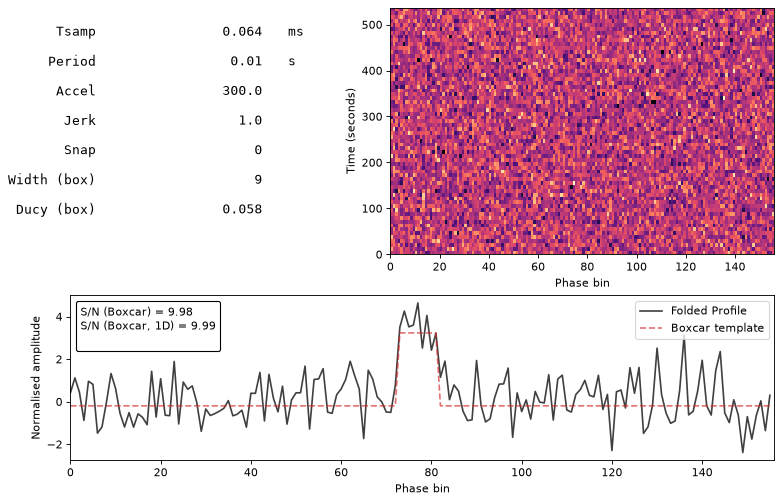

In [2]:
accel, jerk = 300.0, 1.0
mod_kwargs = {"acc": accel, "jerk": jerk}
cfg = PulseSignalConfig(
    period=0.010,
    dt=64e-6,
    nsamps=2**23,
    snr=10,
    ducy=0.1,
    mod_kwargs=mod_kwargs,
    seed=SEED,
)
tim_data = cfg.generate(shape="gaussian")
print(f"T_obs = {cfg.tobs:.1f} s, true frequency = {cfg.freq:.6f} Hz")
tim_data.plot_fold(cfg.freq, cfg.fold_bins, mod_kwargs=mod_kwargs, dpi=80)
plt.show()

## Search configuration

The jerk range is ±1.5 m/s³. `ParamLimits.from_upper` widens the
acceleration and frequency intervals by the drift that jerk range can
cause over the observation. `eta=2` allows two bins of drift between
neighbouring trials, a coarser grid that keeps the 3-D search small.

In [3]:
limits = ParamLimits.from_upper(cfg.freq, [jerk, accel], (-1.5, 1.5), cfg.tobs)
for name, (lo, hi) in zip(["jerk", "accel", "freq"], limits.limits, strict=True):
    print(f"{name:>5}: [{lo:.6g}, {hi:.6g}]")


def search_config(use_fourier: bool) -> PulsarSearchConfig:
    return PulsarSearchConfig(
        nsamps=cfg.nsamps,
        tsamp=cfg.dt,
        nbins=64,
        eta=2,
        param_limits=limits.limits,
        bseg_brute=cfg.nsamps // 128,
        ducy_max=0.2,
        wtsp=1.5,
        nthreads=NTHREADS,
        use_fourier=use_fourier,
    )


true_values = {"jerk": jerk, "accel": accel, "freq": cfg.freq}
results = {}
for use_fourier in (False, True):
    mode = "Fourier" if use_fourier else "time"
    plan, pgram = ffa_search(tim_data, search_config(use_fourier))
    results[mode] = pgram
    print(f"--- {mode} domain: {pgram.snrs.size:,} trials")
    print(pgram.get_indices_summary(true_values=true_values))
    print(pgram.get_summary())

 jerk: [-1.5, 1.5]
accel: [-102.653, 702.653]
 freq: [99.9551, 100.045]
--- time domain: 21,778,120 trials
True param indices: (21, 77, 385)
Best param indices: (np.int64(23), np.int64(74), np.int64(386), np.int64(4))
Best S/N: 8.41
Best Period: 0.009999994185366253
Best jerk: 1.2115384615384617
Best accel: 284.41342513548386
Best freq: 100.00005814637127
Best width: 6


--- Fourier domain: 21,778,120 trials
True param indices: (21, 77, 385)
Best param indices: (np.int64(21), np.int64(77), np.int64(385), np.int64(4))
Best S/N: 8.18
Best Period: 0.010000005814640509
Best jerk: 0.980769230769231
Best accel: 300.0
Best freq: 99.99994185362873
Best width: 6


## Periodograms

Slices through the best trial along each parameter and across each pair
of parameters (time domain; the last plot is the acceleration-jerk plane
in the Fourier mode). The jerk grid is coarse (`eta=2`), so the nearest
jerk trial can be a fraction of a step away from the true value.

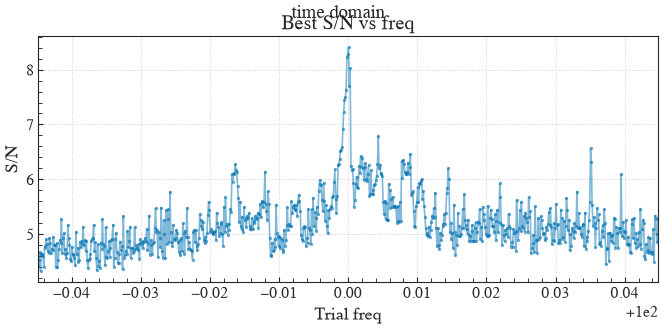

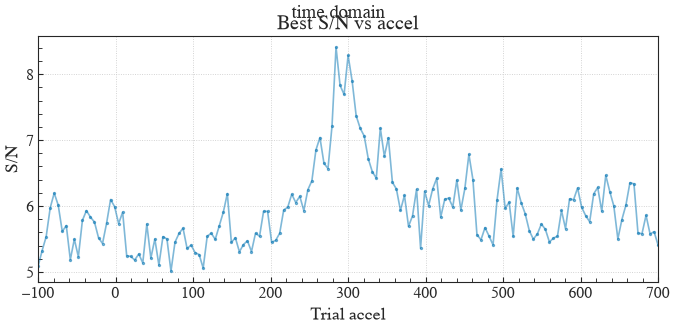

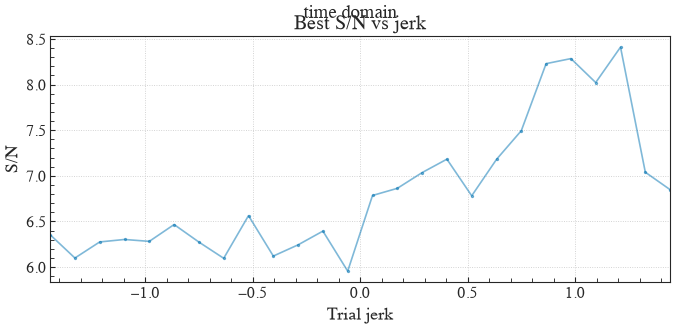

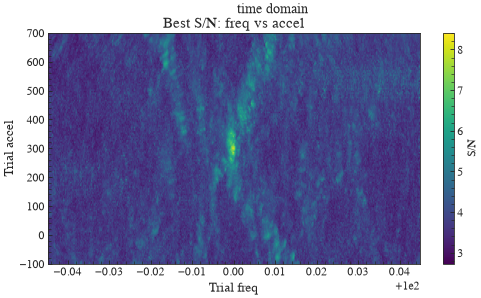

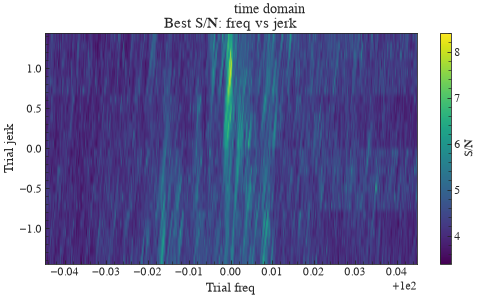

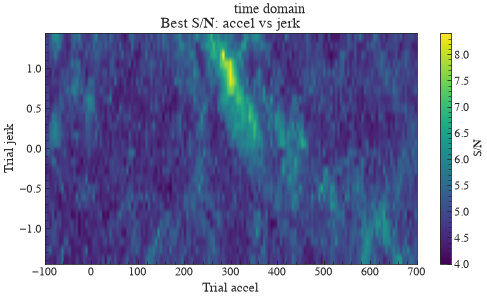

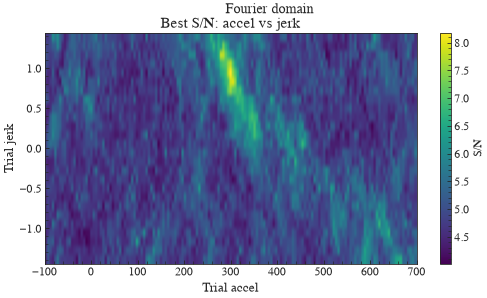

In [4]:
pgram = results["time"]
for param in ("freq", "accel", "jerk"):
    fig = pgram.plot_1d(param, figsize=(10, 4), dpi=80)
    fig.suptitle("time domain")
    plt.show()
for x, y in (("freq", "accel"), ("freq", "jerk"), ("accel", "jerk")):
    fig = pgram.plot_2d(x, y, figsize=(10, 5), dpi=60)
    fig.suptitle("time domain")
    plt.show()
fig = results["Fourier"].plot_2d("accel", "jerk", figsize=(10, 5), dpi=60)
fig.suptitle("Fourier domain")
plt.show()

## Time vs Fourier domain

The Fourier mode lands on the true grid point. The time-domain best lies
a few steps away, along the direction in which a change of jerk is
almost cancelled by a change of acceleration, at a similar S/N: with
whole-bin shifts, that neighbouring trial happens to fold the pulse
slightly better.

In [5]:
print(
    f"{'mode':>8}  {'best S/N':>8}  {'jerk':>6}  {'accel':>7}  {'freq error (Hz)':>15}",
)
for mode, pgram in results.items():
    best = pgram.find_best_params()
    print(
        f"{mode:>8}  {best['snr']:8.2f}  {best['jerk']:6.3f}  {best['accel']:7.1f}  "
        f"{best['freq'] - cfg.freq:15.2e}",
    )

    mode  best S/N    jerk    accel  freq error (Hz)
    time      8.41   1.212    284.4         5.81e-05
 Fourier      8.18   0.981    300.0        -5.81e-05
